In [1]:
%load_ext autoreload
%autoreload
import matplotlib.pyplot as plt
import numpy as np

import evoscape.landscape_visuals as vis
import evoscape.morphogen_regimes as mr

from evoscape.modules import *
from evoscape.landscapes import Landscape, Somitogenesis_Landscape

from cmcrameri import cm

In [2]:

plt.style.use("default")
plt.rcParams.update({"figure.dpi": 200})

In [3]:
order_colors = (
    'tab:green',
    'lightblue',
    'tab:blue',
    'lightcoral',
    'tab:purple',
    'cyan',
)

In [4]:
def add_phase_plots(
    land,
    xx,
    yy,
    t,
    n_grid=25,
    manifold_step_size=0.025,
    manifold_steps=1000,
    basin_dt=0.02,
    basin_steps=2000,
    fp_tol=1e-2,
    vel_tol=2e-3,
    cycle_window=600,
):
    x_range = (float(np.min(xx)), float(np.max(xx)))
    y_range = (float(np.min(yy)), float(np.max(yy)))

    fixed_points = land.find_fixed_points(t, x_range, y_range, n_grid=n_grid)

    saddle_manifolds = land.find_saddle_manifolds(
        t,
        fixed_points=fixed_points,
        x_range=x_range,
        y_range=y_range,
        step_size=manifold_step_size,
        n_steps=manifold_steps,
        termination_tol=fp_tol,
        velocity_tol=vel_tol,
    )

    phase_result = land.find_phase_objects_manifold(
        t,
        xx,
        yy,
        fixed_points=fixed_points,
        saddle_manifolds=saddle_manifolds,
        dt=basin_dt,
        n_steps=basin_steps,
        fp_tol=fp_tol,
        vel_tol=vel_tol,
        cycle_window=cycle_window,
    )

    basin_grid = land.find_attractor_basins_manifold(phase_result=phase_result)

    _, basin_ax, _ = vis.plot_attractor_basins_t(
        land,
        xx,
        yy,
        t,
        phase_result=phase_result,
        basin_grid=basin_grid,
        show_saddle_manifolds=True,
        nullclines=False,
        basin_coloring='module',
        module_order_colors=order_colors,
    )

    _, skeleton_ax, _ = vis.plot_phase_skeleton_t(
        land,
        xx,
        yy,
        t,
        phase_result=phase_result,
        show_saddle_manifolds=True,
        plot_stable_manifolds=False,
        basin_coloring='module',
        module_order_colors=order_colors,
    )

    return phase_result, basin_grid


In [ ]:
L = 2
npoints = 401
q = np.linspace(-L, L, npoints)
xx, yy = np.meshgrid(q,q, indexing = 'xy')

## Binary choice

In [ ]:
x_fate = 1.8 #1.8 for double homoclinic, 1.1 for double SNIC
sig = 0.5
y_cycle = 0.

oscillator = False



## Landscape as function of theta1, theta2

In [ ]:


def update_landscape(p1, p2):
    # # ___
    # modules = [
    #     Node(x=-0.0, y=0.8, a=4., s=0.8),
    #
    #     Node(x=-1.1, y=-1., a=a_left, s=0.75+0.01),
    #     Node(x=+1.1, y=-1., a=a_right, s=0.75),
    x0 = ()
    return Landscape(modules, A0=0.05, x0=x0, regime=mr.mr_const, n_regimes=1)

In [ ]:
theta1, theta2 = (0., 0.)

land = update_landscape(theta1, theta2)
fig = vis.visualize_landscape_t(land, xx, yy, t=0., traj_times=(0, 20, 401), traj_init_cond=(0., 0.), traj_start=100,
circle_opacity=0.1)
plt.show()
res, grid = add_phase_plots(land, xx, yy, t=0.)
plt.show()

## Landscape as a function of time (sigmoidal theta2)

In [5]:
theta1 = (0., 0.)
theta2 = (0.9, -0.9)  ##

def thetas(t, t0, tau):
    t = np.asarray(t)
    tanh = np.tanh((t[..., None] - t0) / 2. / tau)
    theta1_t = theta1[0] + (theta1[1] - theta1[0]) / 2. * (1 + tanh)
    theta2_t = theta2[0] + (theta2[1] - theta2[0]) / 2. * (1 + tanh)
    return theta1_t, theta2_t

def two_controls(t, a, s, t0, tau, **kwargs):
    t = np.asarray(t)
    theta1_t, theta2_t = thetas(t, t0, tau)
    s_t = s[0] * np.exp( s[1] * theta1_t/2 + s[2] * theta2_t/2 )
    a_t = a * np.ones_like(s_t)
    return s_t, a_t


In [7]:
# tt = np.linspace(-3., 25, 301)
# p1, p2 = thetas(tt, 12, 2.)
# plt.figure(figsize=(6, 2.5))
# plt.scatter(tt, -p2, cmap=cm.lipari, c=range(len(tt)), lw=5)
# plt.axis('off')
# plt.show()
#
#
# P = np.zeros((100, 301))
# for i in range(100):
#     _, p2 = thetas(tt, i*18/100, 2.)
#     P[i] = p2.T
#
# aspect = 1.95 # 0.9 for binary choice, 0.95 for umbilic
# plt.imshow(-P, cmap=cm.lipari, aspect=aspect, alpha=1.)
# plt.xticks([])
# plt.yticks([])
# plt.show()


In [1267]:
# snic: t=-3.1
# heteroclinic = t =-0.1

# umbilic homoclinic : t = -1.5; flip : -0.0302748

tau = 2.

if oscillator:
    modules = [
        Node(x=-0.0, y=0., a=4., s=(sig, 0., 1), tau=tau),
        Node(x=-x_fate*100, y=0., a=4.51, s=(sig, -1, -1), tau=tau),
        Node(x=+x_fate, y=0., a=4.5, s=(sig, 1, -1), tau=tau),
        UnstableNode(x=0.0, y=0, a=6., s=(sig*0.8, 0., 1), tau=tau),
        Center(x=0, y=0., a=4., s=(sig*0.85, 0., 1), tau=tau)
    ]
else:
    modules = [
        Node(x=-0.0, y=0., a=4., s=(sig, 0., 1), tau=tau),
        Node(x=-x_fate*100, y=0., a=4.51, s=(sig, -1, -1), tau=tau),
        Node(x=+x_fate, y=0., a=4.5, s=(sig, 1, -1), tau=tau),
    ]
land = Somitogenesis_Landscape(modules, A0=0.05, x0=(0., 0.), regime=two_controls, n_regimes=3)


In [573]:
# flip with cusp landscape  - ?

# L = 2
# npoints = 401
# q = np.linspace(-L, L, npoints)
# xx, yy = np.meshgrid(q,q, indexing = 'xy')
#
# x_fate = 0.8
# y_cycle = 0.8
# y_fate = -1.
# sig=0.5 # 0.6
# tau = 2.
#
#
# y_cycle=0.7
#
# modules = [
#     Node(x=-0.0, y=y_cycle, a=3., s=(sig, 0, +1), tau=tau),
#     Node(x=-x_fate, y=y_fate, a=5.05, s=(sig, -1, +1), tau=tau),
#     Node(x=+x_fate, y=y_fate, a=5., s=(sig, +1, +1), tau=tau), # a = 5
#     Node(x=0.0, y=y_fate, a=3., s=(1.*0.5, 0, -1), tau=tau),
# ]
# land = Somitogenesis_Landscape(modules, A0=0.05, x0=(0., -1.), regime=two_controls, n_regimes=3)




## Kymographs

Initialize with a phase gradient

In [ ]:
t = -10.
fig = vis.visualize_landscape_t(land, xx, yy, t=t, traj_times=(0, 20, 401), traj_init_cond=(0., 0.), traj_start=100,
circle_opacity=0.1)
plt.show()
res, grid = add_phase_plots(land, xx, yy, t=t)
plt.show()

(-15.0, 315.0, 12.0, 1.0)

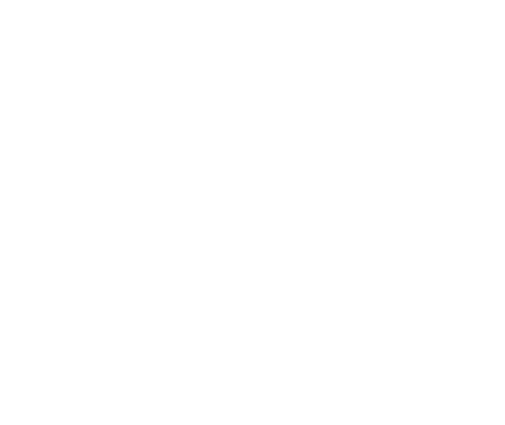

In [1315]:
# plt.figure(figsize=(3, 2.5))
# (dX, dY), pot, rot = land(12, (xx,yy), return_potentials=True)
# plt.plot(pot[200, 100:], c='seagreen', lw=7)
# plt.ylim((-3, 1))
# plt.axis('off')

In [1157]:
res

{'attractors': [{'id': 0,
   'type': 'fixed_point',
   'point': array([-1.63227072, -0.07653759]),
   'fixed_point_index': 0,
   'eigenvalues': array([-2.21882699+0.j, -4.44310768+0.j]),
   'node_id': 1},
  {'id': 1,
   'type': 'fixed_point',
   'point': array([1.63166162, 0.07692548]),
   'fixed_point_index': 4,
   'eigenvalues': array([-2.19965475+0.j, -4.43097773+0.j]),
   'node_id': 2},
  {'id': 2,
   'type': 'cycle',
   'center': array([ 0.00247139, -0.00378354]),
   'radius_mean': 0.9289009817116092,
   'radius_span': 0.027091504639141117,
   'period_steps': 210,
   'period': 4.2,
   'recurrence_distance': 0.0009733135172246853,
   'trajectory': array([[ 0.50852321, -0.76742136],
          [ 0.5317969 , -0.75153269],
          [ 0.55456652, -0.73496134],
          [ 0.57680973, -0.71772259],
          [ 0.59850505, -0.69983221],
          [ 0.61963205, -0.68130636],
          [ 0.64017133, -0.66216153],
          [ 0.66010467, -0.64241444],
          [ 0.6794151 , -0.62208201],
 

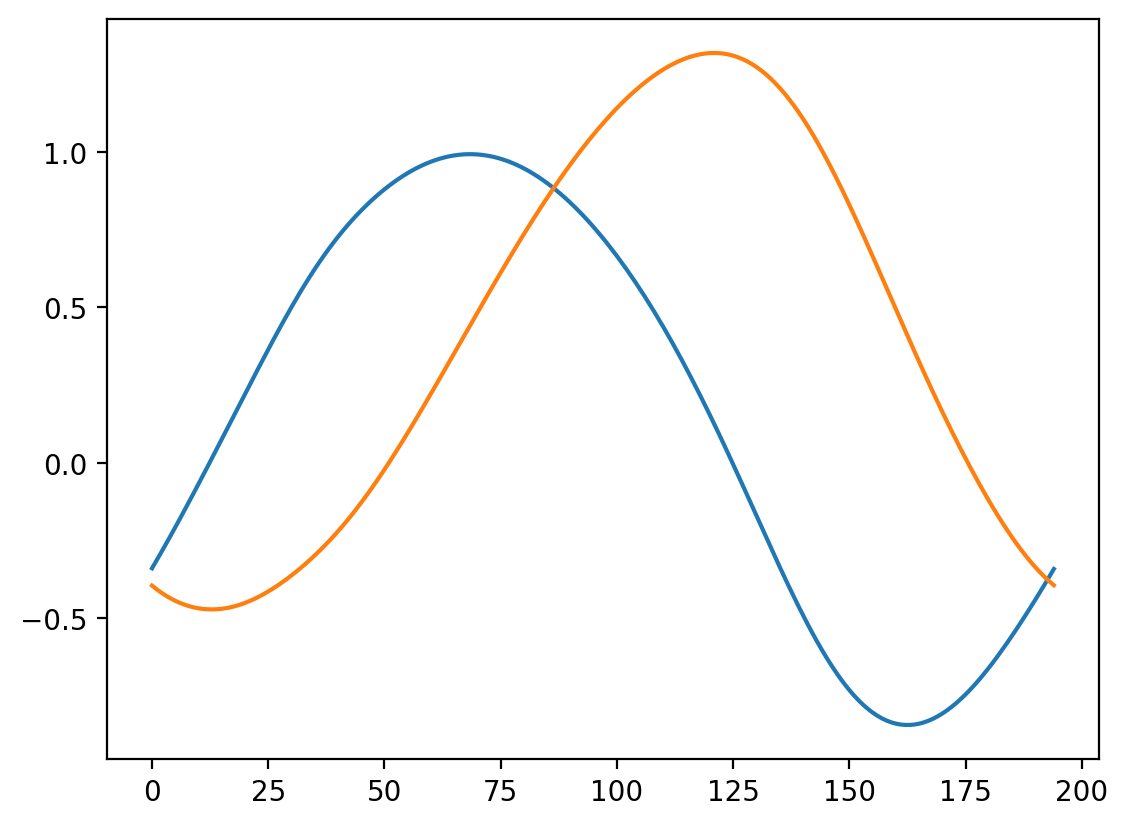

In [1180]:
ind = 2
period_steps = res['attractors'][ind]['period_steps']
cycle = res['attractors'][ind]['trajectory'][:period_steps+1]

plt.figure(figsize=(3,3))
plt.plot(cycle[:,0], cycle[:,1])
plt.show()
plt.figure(figsize=(3,3))
plt.plot(cycle[:,0])
plt.plot(cycle[:,1])
plt.show()


In [1245]:
# cycle = np.zeros((100, 2))
ncells = len(cycle)

time_pars = (-3., 25., 301) # 301  (-3, 25, 601) for single-homoclinic kymo
# morphogen_times = (0.,)


front_time = 18.

fitness_pars = {
    'ncells': ncells,
    'time_pars': time_pars,
    'init_state': cycle.T,
    # 'init_state': (0., 0.5),
    't0_shift': front_time/ncells,
    'noise': 0.,
    'low_value': -0.5,
    'high_value': 0.5,
    'penalty_weight': 0.,
    't_stable': 1,
    'ndt': 50,
    'states': 'basin_static',
    't_freeze': -10.,
    # 't0': 12.,
}
land.get_fitness(fitness_pars)
plt.plot(land.result[0][:, -1])
plt.show()

0.0

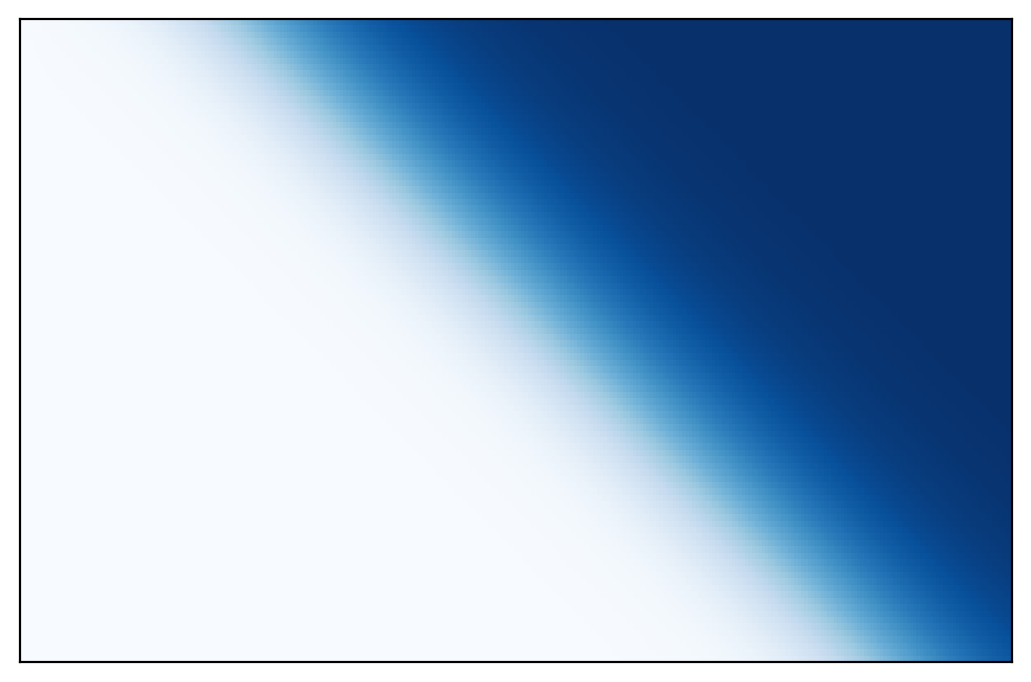

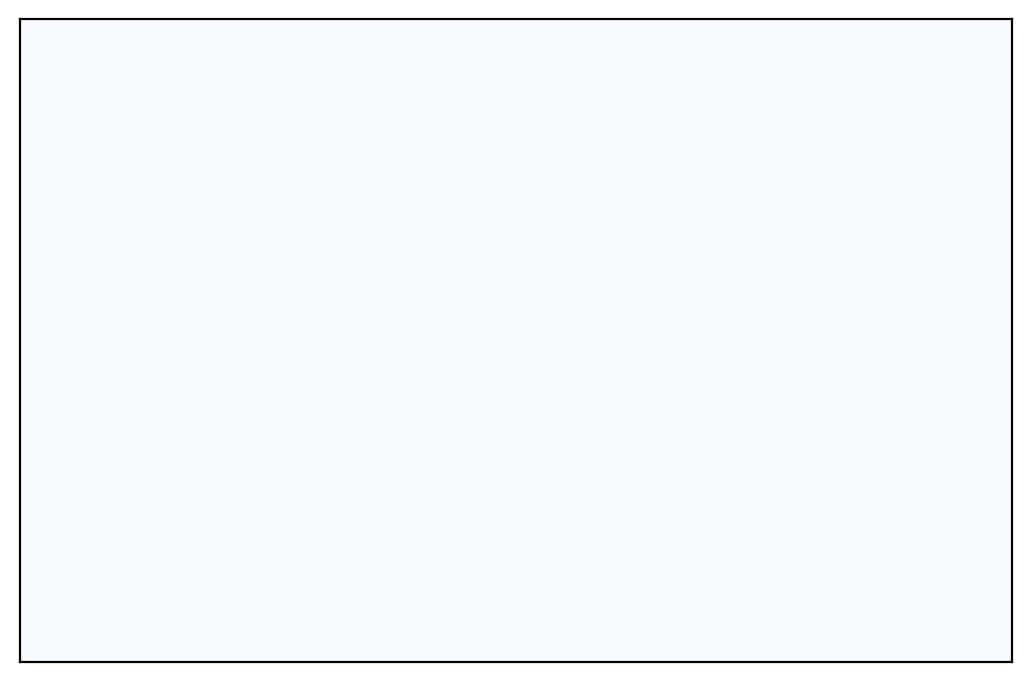

0.0
0.0 0.10265705816364125


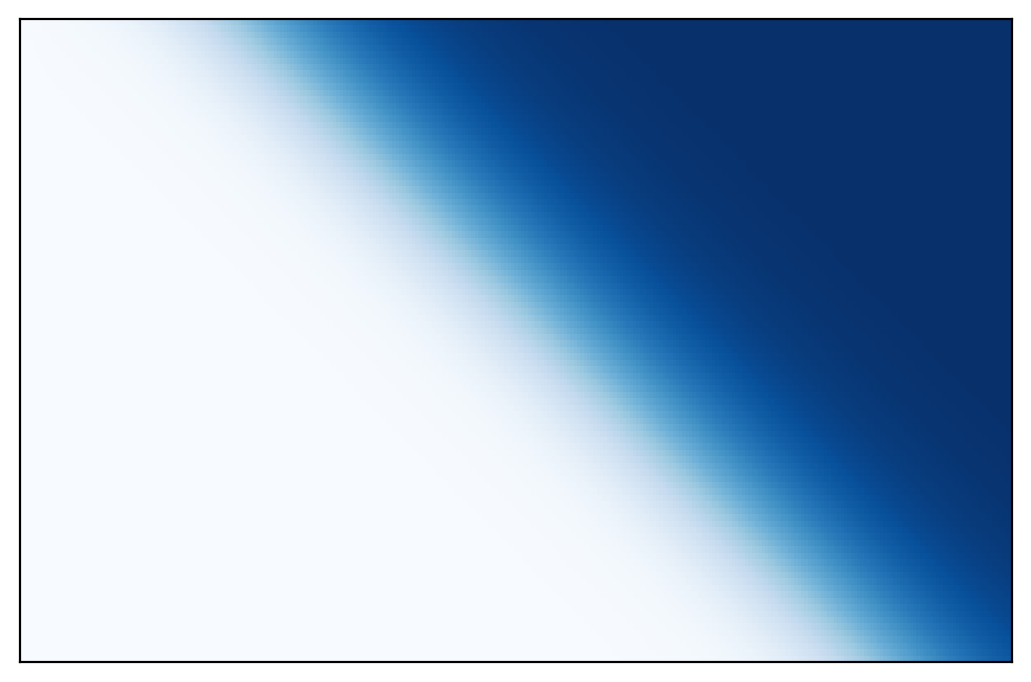

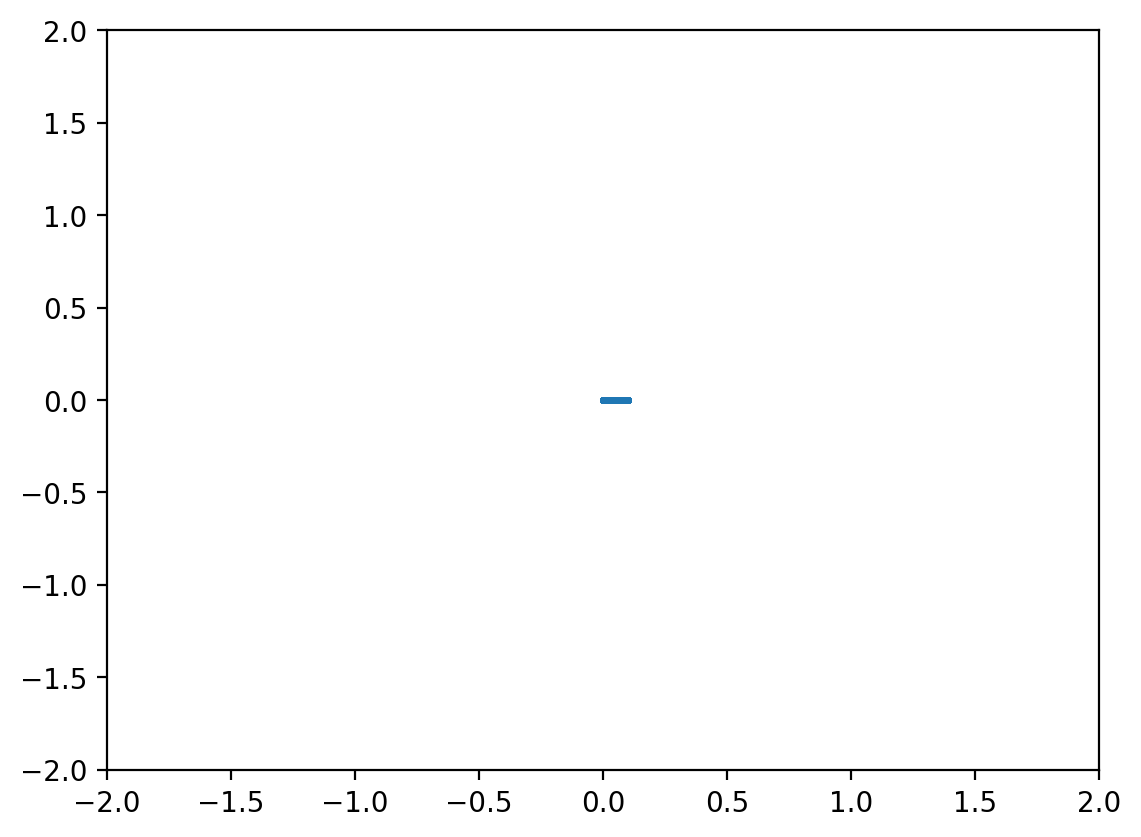

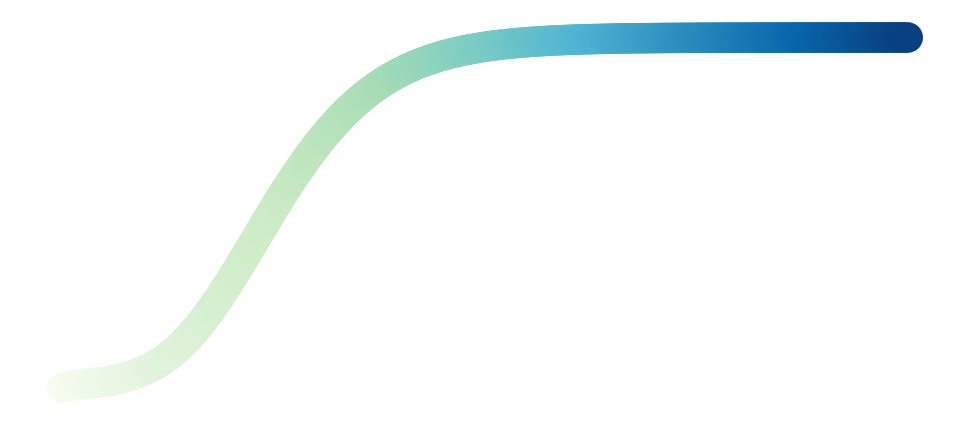

In [1247]:

aspect = 1.95 # 0.9 for binary choice, 0.95 for umbilic
plt.imshow(land.result[0][:, :], cmap='Blues', aspect=aspect)

cells = (32, 51, 71)
# 33, 71 in single homoclinic
# 32, 51, 71 in double homoclinic
# 37, 53, 71 in umbilic flip
colors = ('slateblue', 'deepskyblue', 'lightskyblue', 'indianred')
cmaps = ('Purples', 'Blues', 'Reds')

for i, cell in enumerate(cells):
    plt.hlines(cell, 0, 300, color=colors[i], lw=2)

plt.xticks([])
plt.yticks([])
plt.show()


plt.imshow(-land.result[1], cmap='Blues', aspect=aspect)
plt.xticks([])
plt.yticks([])
plt.show()

r2 = land.result[0]**2+(land.result[1]-y_cycle)**2
plt.imshow(np.sqrt(r2), cmap='Blues', aspect=aspect)

for i, cell in enumerate(cells):
    plt.hlines(cell, 0, 300, color=colors[i], lw=2)

# print(np.min(np.sqrt(r2)), np.max(np.sqrt(r2)))
plt.xticks([])
plt.yticks([])
plt.show()

# ____________________________________
nt = 250
start = 70

for i, cell in enumerate(cells):
    plt.scatter(land.result[0][cell, :nt], land.result[1][cell, :nt], c=tt[:nt], cmap='Purples', s=10, vmin=start)

plt.xlim(-L,L)
plt.ylim(-L,L)
ax=plt.gca()
ax.set_aspect('equal')
plt.axis('off')
plt.show()

############# Make plot as a function of time ! #######

# cbar = plt.colorbar(aspect=10)
# cbar.set_ticks([])



# Fig 1
# cell = 0
# plt.scatter(land.result[0][cell, :], land.result[1][cell, :], s=2)
# plt.xlim((-L, L))
# plt.ylim((-L, L))
# plt.show()
#
# tt = np.linspace(-3., 25, 301)
# #
# plt.figure(figsize=(6, 2.5))
# # plt.plot(tt, -p2, lw=5, c='steelblue')
#
# plt.scatter(tt, land.result[0][0, :], lw=5, cmap='GnBu', c=range(len(tt)))
# plt.axis('off')
# plt.show()



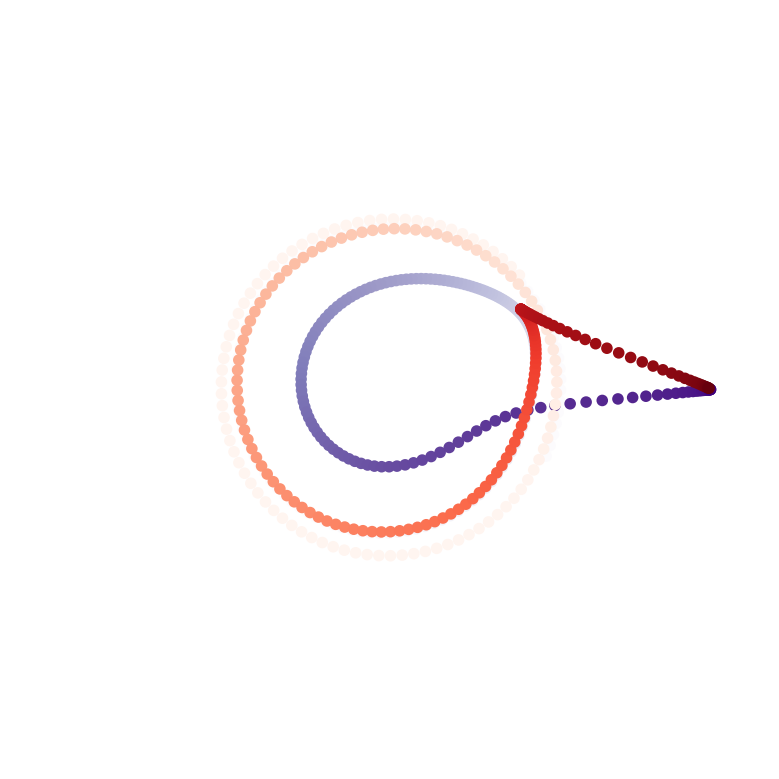

In [1177]:

# theta = np.arctan2(land.result[1], land.result[0])
# tt = np.arange(land.result[0].shape[1])
# xx = np.arange(land.result[0].shape[0])

# integral = np.sum(np.abs(land.result[1]), axis = 1)



# for cell in range(32, 72, 4):  # for heteroclinic
# (37, 53, 71) for umbilic flip

# for cell in range(32, 72, 1):
    # x =xx[cell]*np.ones(nt)
    # theta_init = theta[cell, 0]*np.ones(nt)
    # plt.scatter(land.result[0][cell, :nt], land.result[1][cell, :nt], c=integral[cell]*np.ones(nt), cmap='Blues', s=2, vmin=integral[33], vmax=integral[78])
    # plt.scatter(land.result[0][cell, :nt], land.result[1][cell, :nt], c='w', s=2)

    # plt.scatter(land.result[0][cell, :nt], land.result[1][cell, :nt], c=x, cmap='Greys', s=5, alpha=0.6, vmin=20, vmax=72, edgecolors='none')

    # plt.scatter(land.result[0][cell, :nt], land.result[1][cell, :nt], c=tt[:nt], cmap='Greys', s=5, alpha=0.6, vmin=100, vmax=220, edgecolors='none')
    # pass


# cbar = plt.colorbar(aspect=10)
# cbar.set_ticks([])

# start = 70 #55

# cell=33
# c='slateblue'
# plt.plot(land.result[0][cell, start:nt], land.result[1][cell, start:nt], c=c, lw=2.5)
# plt.scatter(land.result[0][cell, :nt], land.result[1][cell, :nt], c=tt[:nt], cmap='Purples', s=10, vmin=start)

# start = 50
# cell=52
# c='lightskyblue'
# plt.plot(land.result[0][cell, start:nt], land.result[1][cell, start:nt], c=c, lw=2.5)
# plt.scatter(land.result[0][cell, :nt], land.result[1][cell, :nt], c=tt[:nt], cmap='GnBu', s=10, vmin=start)
# cell=51
# c='lightskyblue'
# plt.plot(land.result[0][cell, start:nt], land.result[1][cell, start:nt], c=c, lw=2.5)
# plt.scatter(land.result[0][cell, :nt//2], land.result[1][cell, :nt//2], c=tt[:nt//2], cmap='Blues', s=10, vmin=start, vmax=nt)

# cell=71
# c='indianred'
# # plt.plot(land.result[0][cell, start:nt], land.result[1][cell, start:nt], c=c, lw=2.5)
# plt.scatter(land.result[0][cell, :nt], land.result[1][cell, :nt], c=tt[:nt], cmap='Reds', s=10, vmin=start)
#
#
# cell=51
# c='lightskyblue'
# plt.plot(land.result[0][cell, start:nt], land.result[1][cell, start:nt], c=c, lw=2.5)
# plt.scatter(land.result[0][cell, nt//2:nt], land.result[1][cell, nt//2:nt], c=tt[nt//2:nt], cmap='Blues', s=10, vmin=start, vmax=nt)



# cell=-1
# c='#49793F'
# nt = 200
# plt.plot(land.result[0][cell, start:nt], land.result[1][cell, start:nt], c=c, zorder=100, lw=3)

#
# plt.xlim(-2,2)
# plt.ylim(-2,2)
# ax=plt.gca()
# ax.set_aspect('equal')
# plt.axis('off')
# plt.show()

### Loop-flip

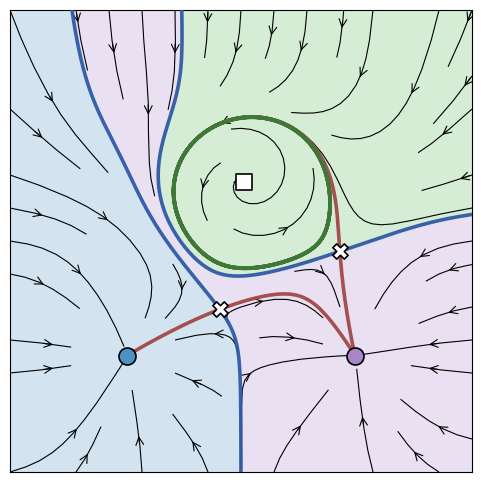

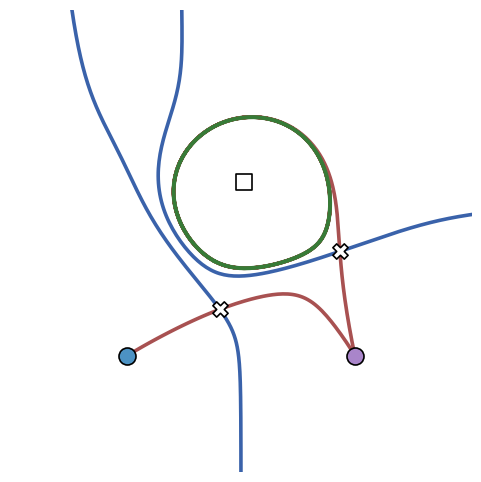

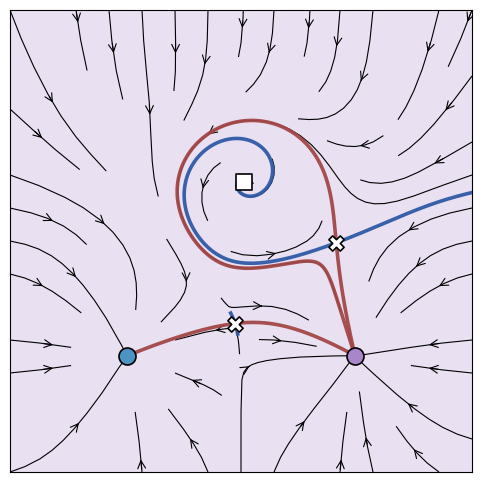

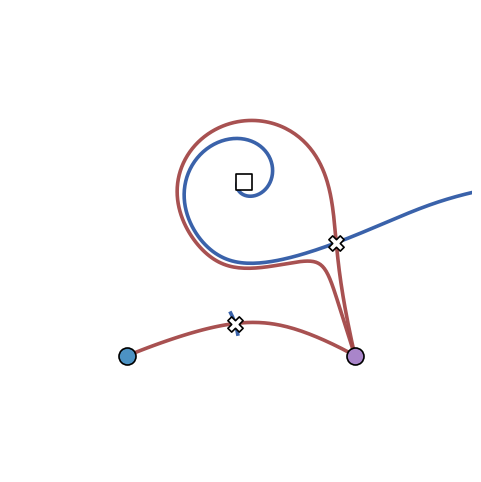

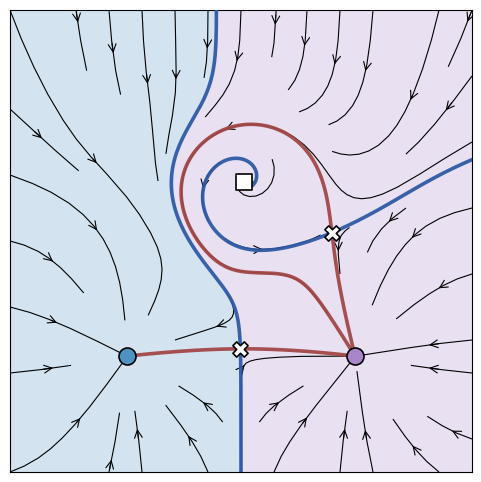

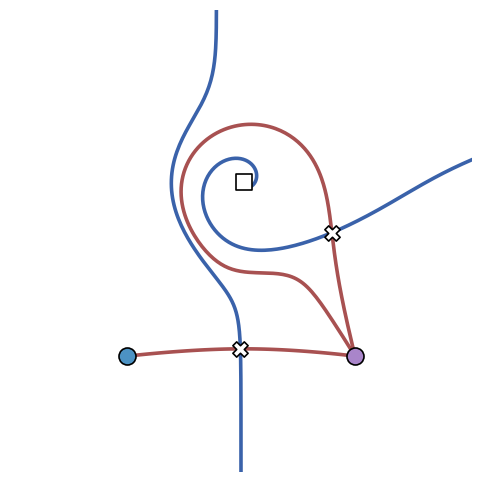

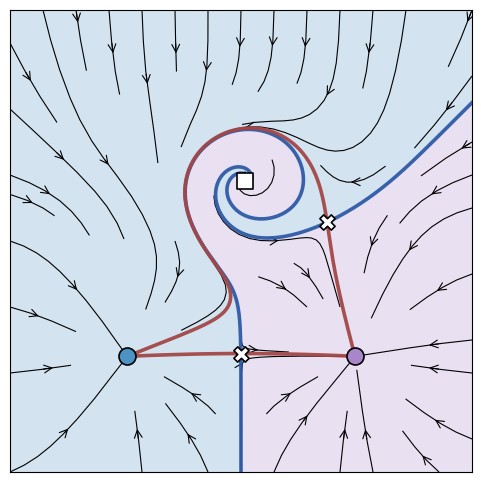

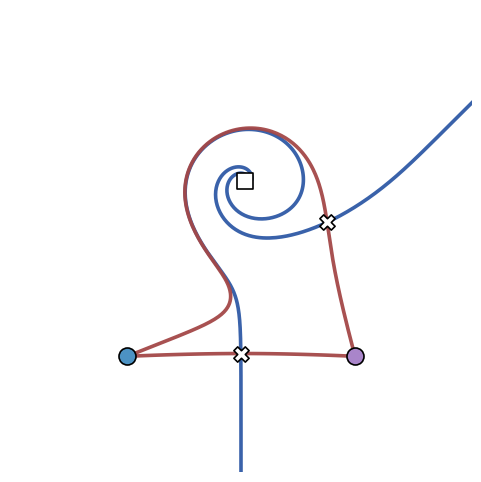

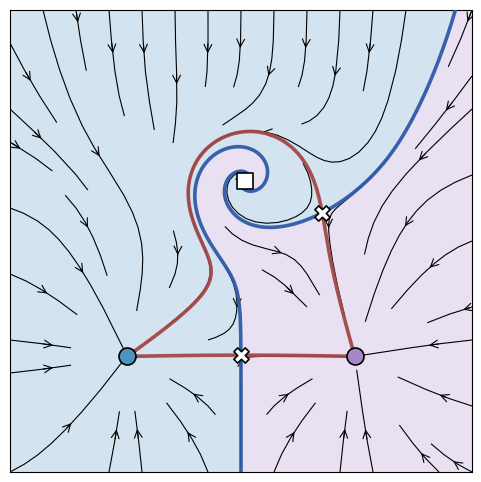

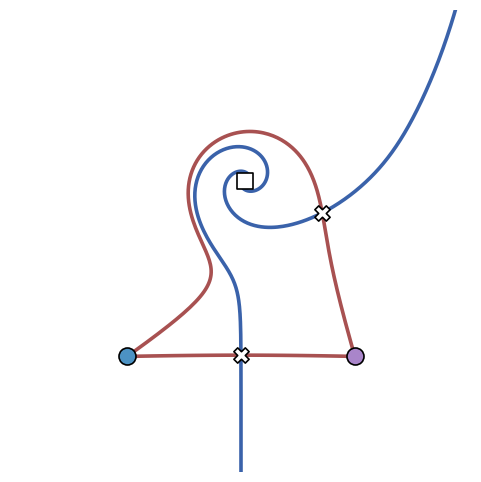

In [133]:
# for t in (-1.3, 0.26, 2., 5.):
for t in (-2., -1., 0., 1., 2.):

    # fig = vis.visualize_landscape_t(land, xx, yy, t=t, traj_times=(0, 20, 401), traj_init_cond=(-0., 0.), traj_start=100, circle_opacity=0.2)
    res, grid = add_phase_plots(land, xx, yy, t=t)

## Plot basin states

In [45]:
states = land.get_cell_states(0., coordinate=(land.result[0].flatten(), land.result[1].flatten()), measure='basin static', basin_grid=grid)
states=np.reshape(states, land.result[0].shape)

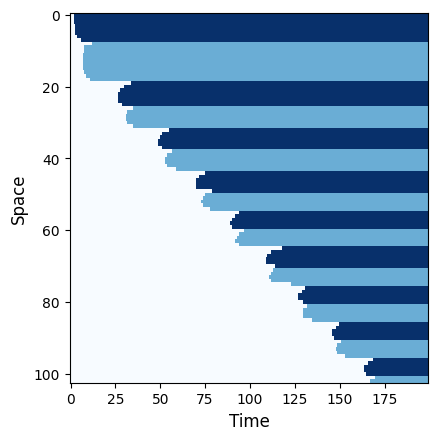

In [46]:
plt.imshow(states[:, :200], cmap='Blues', aspect=2, interpolation='none')
plt.xlabel('Time', fontsize=12)
plt.ylabel('Space', fontsize=12)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Space', fontsize=12)
plt.xlabel('Time', fontsize=12)
plt.ylabel('Space', fontsize=12)
plt.show()